# Implementação diferenciável da característica de Euler

## Importações

In [8]:
import random
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import datasets

# Código .py auxiliar
from 0_nucleo import (
    euler_exato,
    caracteristica_euler_suave_4,
    caracteristica_euler_suave_8,
    TEMPERATURA_PADRAO,
    LIMIAR
)

## Configurações

In [9]:
PASTA_MNIST = Path("datasets/MNIST")
PASTA_TILE = Path("datasets/MVTecAD/tile")

N_IMAGENS = 2000      # digitos do MNIST analisados
SEED = 18

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# MNIST (apenas as imagens) - importa apenas o valor da sua caracteristica de Euler
base = datasets.MNIST(root=PASTA_MNIST, train=False, download=True)
imagens = (base.data[:N_IMAGENS].float() / 255.0).unsqueeze(1)
print("Imagens:", tuple(imagens.shape))


Imagens: (2000, 1, 28, 28)


## Teste 1
Verifica se a implementação suave consegue reproduzir o resultado exato em imagens binárias.

In [11]:
# Cria 300 imagens com pixels aleatórios entre 0 e 1
# 'F.avg_pool2d(..., 3, 1, 1)' aplica uma média local em janelas de 3 × 3 pixels, criando uma correlação espacial entre os pixels vizinhos
aleatorias = (F.avg_pool2d(torch.rand(300, 1, 34, 34), 3, 1, 1) > 0.5).float()[:, :, 1:-1, 1:-1]

# Calcula a característica de Euler exata
# OBS.: 4 e 8 = nº de vizinhos considerados em dois pixels conectados
exato_4 = np.array([euler_exato(m[0].numpy(), conectividade=1) for m in aleatorias])
exato_8 = np.array([euler_exato(m[0].numpy(), conectividade=2) for m in aleatorias])

# Calcula a aproximação suave com temperatura 0,01
suave_4 = caracteristica_euler_suave_4(aleatorias, 0.01).numpy()
suave_8 = caracteristica_euler_suave_8(aleatorias, 0.01).numpy()

print("Vizinhanca 4 | erro maximo vs scikit-image:", np.abs(suave_4 - exato_4).max())
print("Vizinhanca 8 | erro maximo vs scikit-image:", np.abs(suave_8 - exato_8).max())
print("Intervalo de chi nas imagens sorteadas:", exato_4.min(), "a", exato_4.max())


Vizinhanca 4 | erro maximo vs scikit-image: 0.0
Vizinhanca 8 | erro maximo vs scikit-image: 0.0
Intervalo de chi nas imagens sorteadas: -8 a 32


## Teste 2
Distribuição da característica de Euler no MNIST

  chi    imagens (viz. 4)    imagens (viz. 8)
   -4                   0                   1
   -3                   0                   3
   -2                   3                  10
   -1                 102                 149
    0                 538                 591
    1                1175                1211
    2                 113                  30
    3                  29                   3
    4                  20                   1
    5                   3                   0
    6                   5                   1
    7                   4                   0
    8                   4                   0
    9                   1                   0
   10                   3                   0


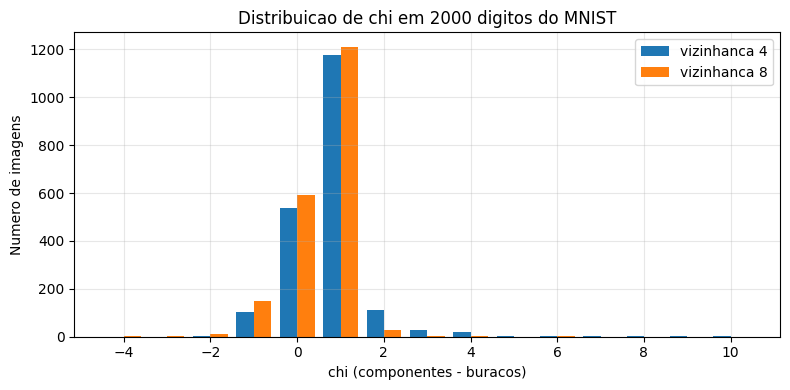

In [12]:
# Calcula a característica de Euler (chi) exata para as 2.000 imagens do MNIST
chi_4 = np.array([euler_exato(img[0].numpy(), conectividade=1) for img in imagens])
chi_8 = np.array([euler_exato(img[0].numpy(), conectividade=2) for img in imagens])

# Valores possíveis de chi
valores = np.arange(min(chi_4.min(), chi_8.min()), max(chi_4.max(), chi_8.max()) + 1)
print(f"{'chi':>5s}{'imagens (viz. 4)':>20s}{'imagens (viz. 8)':>20s}")

# Print dos valores encontrados
for v in valores:
    print(f"{v:5d}{int((chi_4 == v).sum()):20d}{int((chi_8 == v).sum()):20d}")

fig, eixo = plt.subplots(figsize=(8, 4))
largura = 0.4

eixo.bar(valores - largura / 2, [(chi_4 == v).sum() for v in valores], width=largura, label="vizinhanca 4")
eixo.bar(valores + largura / 2, [(chi_8 == v).sum() for v in valores], width=largura, label="vizinhanca 8")
eixo.set_xlabel("chi (componentes - buracos)")
eixo.set_ylabel("Numero de imagens")
eixo.set_title(f"Distribuicao de chi em {N_IMAGENS} digitos do MNIST")
eixo.legend()
eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:
# Implementacao suave aplicada a imagens binarizadas (preto/ branco)
# Erro = 0 --> a aproximação suave deve reproduzir a classificação dos pixels e, consequentemente, preservar a característica de Euler exata

binarizadas = (imagens > LIMIAR).float()

erro_4 = np.abs(caracteristica_euler_suave_4(binarizadas, 0.01).numpy() - chi_4).max()
erro_8 = np.abs(caracteristica_euler_suave_8(binarizadas, 0.01).numpy() - chi_8).max()

print("\nImagens binarizadas | erro maximo suave vs exato")
print("  vizinhanca 4:", erro_4)
print("  vizinhanca 8:", erro_8)



Imagens binarizadas | erro maximo suave vs exato
  vizinhanca 4: 0.0
  vizinhanca 8: 0.0


# Teste 3
Visualização de exemplos

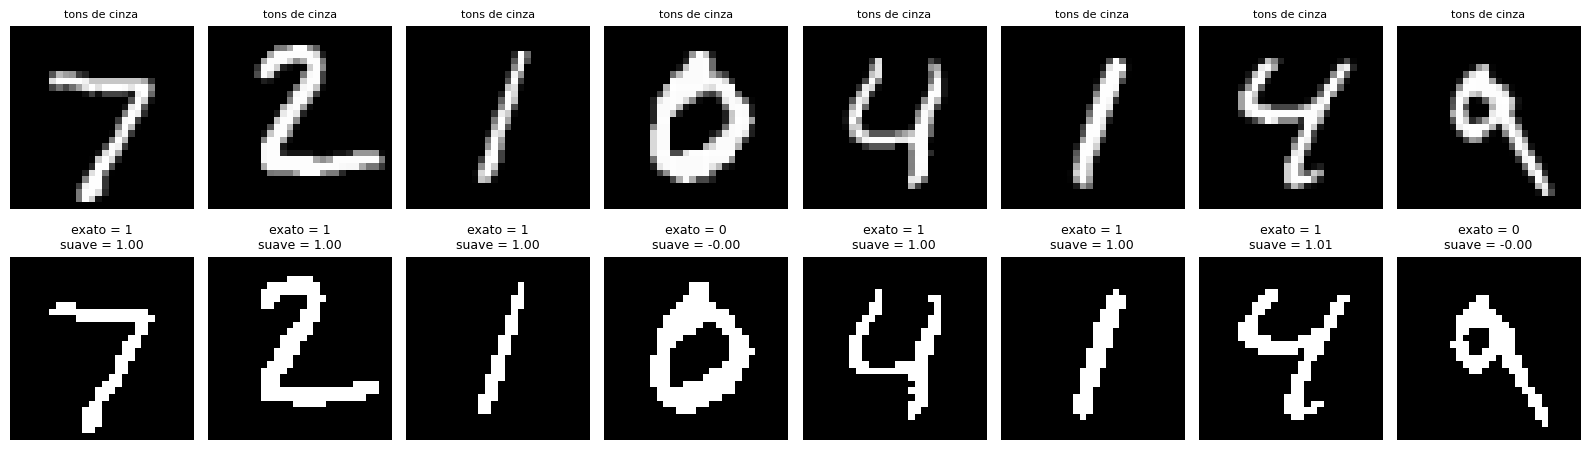

In [4]:
suave_4 = caracteristica_euler_suave_4(imagens, TEMPERATURA_PADRAO).numpy()

fig, eixos = plt.subplots(2, 8, figsize=(16, 4.8))

for i in range(8):
    eixos[0, i].imshow(imagens[i, 0], cmap="gray", vmin=0, vmax=1)
    eixos[0, i].set_title("tons de cinza", fontsize=8)
    eixos[1, i].imshow(imagens[i, 0] > LIMIAR, cmap="gray")
    eixos[1, i].set_title(f"exato = {chi_4[i]}\nsuave = {suave_4[i]:.2f}", fontsize=9)
    eixos[0, i].axis("off")
    eixos[1, i].axis("off")

plt.tight_layout()
plt.show()


## Teste 4
Influência da temperatura nas versões suaves e exatas

Temperatura usada no treinamento: T = 0.02

suave-4 vs exato-4   erro medio =   0.047 | erro maximo =   1.932 | acerto apos arredondar =  98.3%
suave-8 vs exato-8   erro medio =   0.023 | erro maximo =   0.975 | acerto apos arredondar =  99.2%

Erro medio |suave - exato| em funcao da temperatura:
       T    vizinhanca 4    vizinhanca 8
    0.01           0.029           0.014
    0.02           0.047           0.023
    0.05           0.123           0.067
    0.10           4.286           3.628
    0.20          41.212          30.336


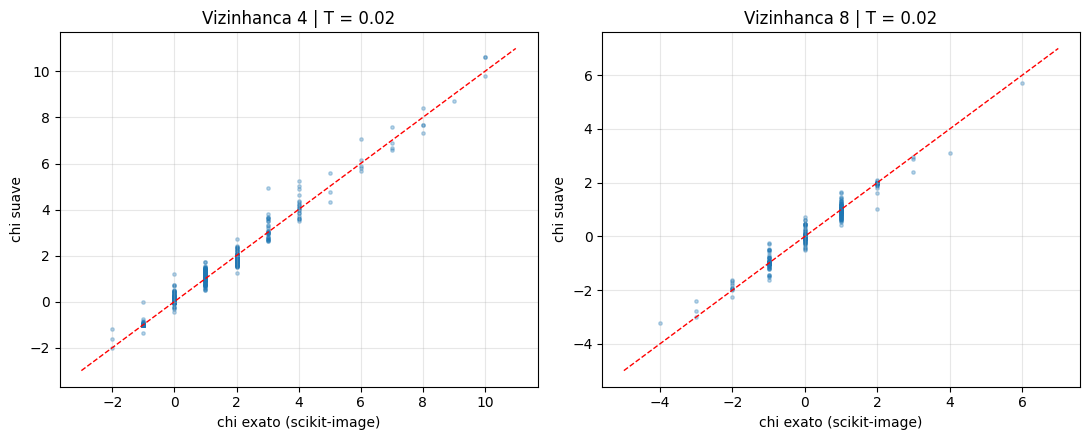

In [14]:
# Resumo de erroos e acertos
def resumo(nome, previsto, exato):
    erro = np.abs(previsto - exato)
    acerto = np.mean(np.round(previsto) == exato) * 100
    print(f"{nome:20s} erro medio = {erro.mean():7.3f} | erro maximo = {erro.max():7.3f} | acerto apos arredondar = {acerto:5.1f}%")

print(f"Temperatura usada no treinamento: T = {TEMPERATURA_PADRAO}\n")

resumo("suave-4 vs exato-4", caracteristica_euler_suave_4(imagens).numpy(), chi_4)
resumo("suave-8 vs exato-8", caracteristica_euler_suave_8(imagens).numpy(), chi_8)

print("\nErro medio |suave - exato| em funcao da temperatura:")
print(f"{'T':>8s}{'vizinhanca 4':>16s}{'vizinhanca 8':>16s}")

# Verificando variação de temperatura
for T in [0.01, 0.02, 0.05, 0.10, 0.20]:
    erro_4 = np.abs(caracteristica_euler_suave_4(imagens, T).numpy() - chi_4).mean()
    erro_8 = np.abs(caracteristica_euler_suave_8(imagens, T).numpy() - chi_8).mean()
    print(f"{T:8.2f}{erro_4:16.3f}{erro_8:16.3f}")

# Visualização
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
for eixo, (titulo, previsto, exato) in zip(eixos, [("Vizinhanca 4", caracteristica_euler_suave_4(imagens).numpy(), chi_4), ("Vizinhanca 8", caracteristica_euler_suave_8(imagens).numpy(), chi_8),]):

    eixo.scatter(exato, previsto, s=6, alpha=0.3)
    limites = [exato.min() - 1, exato.max() + 1]
    eixo.plot(limites, limites, "r--", linewidth=1)
    eixo.set_xlabel("chi exato (scikit-image)")
    eixo.set_ylabel("chi suave")
    eixo.set_title(f"{titulo} | T = {TEMPERATURA_PADRAO}")
    eixo.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Teste 5
Verifica se a perda topológica identifica as diferenças geradas artificialmente nas imagens do dataset e, principalmente, se consegue gerar gradientes para orientar a correção da imagem durante o treinamento

In [15]:
# Seleção de dezesseis imagens originais do MNIST
alvo = imagens[:16]

# Imagens alvo com ruído ("danificadas")
predicao = (alvo + 0.1 * torch.randn_like(alvo)).clamp(0, 1)
predicao.requires_grad_(True)


for nome, funcao in [("suave-4", caracteristica_euler_suave_4), ("suave-8", caracteristica_euler_suave_8),]:
    predicao.grad = None
    perda = torch.mean(torch.abs(funcao(predicao) - funcao(alvo)))
    perda.backward()
    grad = predicao.grad

    print(
        f"{nome} | perda = {perda.item():7.3f} | "
        f"norma do gradiente = {grad.norm().item():7.4f} | "
        f"finito: {bool(torch.isfinite(grad).all())} | "
        f"pixels com gradiente != 0: {(grad.abs() > 1e-8).float().mean().item() * 100:5.1f}%"
    )


suave-4 | perda =   0.043 | norma do gradiente =  0.7264 | finito: True | pixels com gradiente != 0:  12.3%
suave-8 | perda =   0.005 | norma do gradiente =  0.1966 | finito: True | pixels com gradiente != 0:  11.6%


# Teste 6
Verifica a versão suave nas imagens que realmente treinam a rede a seguir e mostra a escala de chi (para calibrar o peso lambda do termo de Euler).

In [16]:
# Funções compartilhadas
from nucleo import listar_imagens, carregar_imagem

# Imagens a serem usadas
arquivos = listar_imagens(PASTA_TILE / "train" / "good")[:20]
tile = torch.stack([carregar_imagem(a) for a in arquivos])

# Calcular euler exato
chi_tile = np.array([euler_exato(t[0].numpy(), conectividade=1) for t in tile])
print("Imagens tile analisadas:", len(tile))
print("chi exato (viz. 4): minimo", chi_tile.min(), "| maximo", chi_tile.max(), "| media", round(float(chi_tile.mean()), 1))
print("\nErro medio |suave - exato| nas imagens tile, por temperatura:")
print(f"{'T':>8s}{'erro medio':>14s}{'pixels ambiguos':>20s}")


# Verificando erro por temperatura
for T in [0.01, 0.02, 0.05, 0.10]:

    erro = np.abs(caracteristica_euler_suave_4(tile, T).numpy() - chi_tile).mean()
    ambiguos = (tile - LIMIAR).abs().lt(T).float().mean().item() * 100

    print(f"{T:8.2f}{erro:14.2f}{ambiguos:19.1f}%")

print("\n'Pixels ambiguos' = fracao de pixels a menos de T do limiar (0.5)")


Imagens tile analisadas: 20
chi exato (viz. 4): minimo -384 | maximo 171 | media -78.5

Erro medio |suave - exato| nas imagens tile, por temperatura:
       T    erro medio     pixels ambiguos
    0.01         89.62                5.5%
    0.02        293.69                9.1%
    0.05       1201.34               23.9%
    0.10       2915.66               47.1%

'Pixels ambiguos' = fracao de pixels a menos de T do limiar (0.5)
